In [44]:
import torch
import random
import torch.nn as nn
import numpy as np
import torch.nn.functional as F

In [45]:
from torch.cuda import is_available
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print("Pytorch version :", torch.__version__)
print("Device :", device)

if torch.cuda.is_available():
  print("GPU NAME :", torch.cuda.get_device_name(0))

else:
  print("GPU unavailable , currently on CPU")


Pytorch version : 2.11.0+cu130
Device : cuda
GPU NAME : Tesla T4


In [46]:
#TESTING RMS NORM

class RMSNorm(nn.Module):
  def __init__(self, dim , eps = 1e-6):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(torch.ones(dim))


  def forward(self , x):

    x_float = x.float()
    rms = torch.sqrt(x_float.pow(2).mean(dim=-1, keepdim= True) + self.eps)

    normalized = (x_float/rms).to(dtype=x.dtype)

    rms_norm = normalized * self.weight

    return rms_norm


#Testing RMS Norm
test_norm = RMSNorm(dim=8).to(device)
test_input = torch.randn(2,4,8, device=device)
test_output = test_norm(test_input)

print("input shape :", test_input.shape)
print("output shape :", test_output.shape)
print("output contains only finite values :", torch.isfinite(test_output).all().item())



input shape : torch.Size([2, 4, 8])
output shape : torch.Size([2, 4, 8])
output contains only finite values : True


In [47]:
#RoPE



def apply_rope(x):
    # x shape: [batch, heads, sequence, head_dimension]
    B, H, T, D = x.shape

    if D % 2 != 0:
        raise ValueError("RoPE requires an even head dimension.")

    x_float = x.float()

    inv_freq = 1.0 / (
        10000 ** (
            torch.arange(0, D, 2, device=x.device).float() / D
        )
    )

    positions = torch.arange(T, device=x.device).float()
    angles = torch.outer(positions, inv_freq)

    cos = angles.cos()[None, None, :, :]
    sin = angles.sin()[None, None, :, :]

    # Rotate adjacent feature pairs: (x0, x1), (x2, x3), ...
    x_even = x_float[..., 0::2]
    x_odd = x_float[..., 1::2]

    rotated_even = x_even * cos - x_odd * sin
    rotated_odd = x_even * sin + x_odd * cos

    result = torch.stack(
        (rotated_even, rotated_odd), dim=-1
    ).flatten(-2)

    return result.to(dtype=x.dtype)


rope_test = torch.randn(2, 4, 16, 32, device=device)
rope_output = apply_rope(rope_test)

print("RoPE shape:", rope_output.shape)
print("RoPE finite:", torch.isfinite(rope_output).all().item())


RoPE shape: torch.Size([2, 4, 16, 32])
RoPE finite: True


In [48]:

class StandardCausalMultiheadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        if self.head_dim % 2 != 0:
            raise ValueError("RoPE requires an even head dimension.")

        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        H = self.num_heads
        D = self.head_dim

        qkv = self.qkv(x).view(B, T, 3, H, D)
        q, k, v = qkv.unbind(dim=2)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        # Rotate queries and keys according to their positions
        q = apply_rope(q)
        k = apply_rope(k)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(D)

        causal_mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        scores = scores.masked_fill(causal_mask, float("-inf"))
        weights = F.softmax(scores, dim=-1, dtype=torch.float32)
        weights = self.attn_dropout(weights)

        output = weights.to(v.dtype) @ v
        output = output.transpose(1, 2).contiguous().view(B, T, C)

        output = self.out_proj(output)
        return self.resid_dropout(output)


In [77]:

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def lambda_init_fn(depth):
    return 0.8 - 0.6 * math.exp(-0.3 * depth)



class DifferentialAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, depth=0, dropout=0.0):
        super().__init__()

        assert embed_dim % (2 * num_heads) == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // (2 * num_heads)
        self.value_dim = 2 * self.head_dim
        self.lambda_init = lambda_init_fn(depth)

        if self.head_dim % 2 != 0:
            raise ValueError("RoPE requires an even head dimension.")

        self.q_proj = nn.Linear(embed_dim, embed_dim, bias=False)
        self.k_proj = nn.Linear(embed_dim, embed_dim, bias=False)
        self.v_proj = nn.Linear(embed_dim, embed_dim, bias=False)
        self.out_proj = nn.Linear(embed_dim, embed_dim, bias=False)

        self.lambda_q1 = nn.Parameter(torch.randn(self.head_dim) * 0.1)
        self.lambda_k1 = nn.Parameter(torch.randn(self.head_dim) * 0.1)
        self.lambda_q2 = nn.Parameter(torch.randn(self.head_dim) * 0.1)
        self.lambda_k2 = nn.Parameter(torch.randn(self.head_dim) * 0.1)

        self.head_norm = RMSNorm(self.value_dim, eps=1e-5)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        H = self.num_heads
        D = self.head_dim

        q = self.q_proj(x).view(B, T, 2 * H, D).transpose(1, 2)
        k = self.k_proj(x).view(B, T, 2 * H, D).transpose(1, 2)
        v = self.v_proj(x).view(B, T, H, 2 * D).transpose(1, 2)

        # Apply RoPE to all Q/K branches before splitting
        q = apply_rope(q)
        k = apply_rope(k)

        q1, q2 = q[:, 0::2], q[:, 1::2]
        k1, k2 = k[:, 0::2], k[:, 1::2]

        scores1 = (q1 @ k1.transpose(-2, -1)) / math.sqrt(D)
        scores2 = (q2 @ k2.transpose(-2, -1)) / math.sqrt(D)

        causal_mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        scores1 = scores1.masked_fill(causal_mask, float("-inf"))
        scores2 = scores2.masked_fill(causal_mask, float("-inf"))

        a1 = F.softmax(scores1, dim=-1, dtype=torch.float32)
        a2 = F.softmax(scores2, dim=-1, dtype=torch.float32)

        # a1 = self.attn_dropout(a1)
        # a2 = self.attn_dropout(a2)

        lambda_1 = torch.exp(
            torch.sum(self.lambda_q1 * self.lambda_k1).float()
        )
        lambda_2 = torch.exp(
            torch.sum(self.lambda_q2 * self.lambda_k2).float()
        )
        lambda_value = lambda_1 - lambda_2 + self.lambda_init

        output = (a1 - lambda_value * a2).to(v.dtype) @ v

        output = self.head_norm(output)
        output = output * (1.0 - self.lambda_init)

        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.out_proj(output)

        return self.resid_dropout(output)



In [52]:
#swiGLU

class SwiGLU(nn.Module):
  def __init__(self, embed_dim, hidden_dim, dropout=0.0):
    super().__init__()

    self.gate_proj = nn.Linear(embed_dim, hidden_dim)
    self.up_proj= nn.Linear(embed_dim , hidden_dim)
    self.down_proj = nn.Linear(hidden_dim, embed_dim)
    self.dropout = nn.Dropout(dropout)


  def forward(self, x):
      gate = F.silu(self.gate_proj(x))
      up =self.up_proj(x)

      hidden = gate * up
      hidden = self.dropout(hidden)

      return self.down_proj(hidden)




In [53]:
class TransformerBlock(nn.Module):
  def __init__(self, embed_dim, num_heads, attention_type="standard", dropout=0.0, depth=0):
    super().__init__()

    self.norm1 = RMSNorm(embed_dim)
    self.norm2 = RMSNorm(embed_dim)

    if attention_type == "standard":
      self.attention = StandardCasualMutiheadAttention(embed_dim = embed_dim, num_heads=num_heads, dropout=dropout)
    elif attention_type == "differential" :
      self.attention =  DifferentialAttention(embed_dim=embed_dim, num_heads=num_heads, dropout=dropout, depth=depth)
    else :
      raise ValueError("attention type must be 'standard' or 'differential'")

    ffn_hidden_dim = (8 * embed_dim) // 3

    self.ffn = SwiGLU(
        embed_dim=embed_dim,
        hidden_dim=ffn_hidden_dim,
        dropout=dropout
    )


  def forward(self, x):

    x = x + self.attention(self.norm1(x))

    x = x + self.ffn(self.norm2(x))

    return x






In [54]:
# Test both block types
standard_block = TransformerBlock(
    embed_dim=32,
    num_heads=4,
    attention_type="standard"
).to(device)

differential_block = TransformerBlock(
    embed_dim=32,
    num_heads=2,
    attention_type="differential"
).to(device)

block_input = torch.randn(2, 4, 32, device=device)

with torch.no_grad():
    standard_block_output = standard_block(block_input)
    differential_block_output = differential_block(block_input)

print("Input shape:", block_input.shape)
print("Standard block output:", standard_block_output.shape)
print("Differential block output:", differential_block_output.shape)
print(
    "Both outputs finite:",
    torch.isfinite(standard_block_output).all().item()
    and torch.isfinite(differential_block_output).all().item()
)


Input shape: torch.Size([2, 4, 32])
Standard block output: torch.Size([2, 4, 32])
Differential block output: torch.Size([2, 4, 32])
Both outputs finite: True


# DATA SET validations and testing


In [55]:
!pip -q install datasets transformers

In [56]:
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

In [57]:
# Load a small tiny stories subset

tokenizer = AutoTokenizer.from_pretrained("gpt2")

if tokenizer.pad_token is None:
  tokenizer.pad_token = tokenizer.eos_token




TRAIN_STORIES = 25_000
VALID_STORIES = 2_500

train_stories = load_dataset(
    "roneneldan/TinyStories",
    split=f"train[:{TRAIN_STORIES}]"
)

valid_stories = load_dataset(
    "roneneldan/TinyStories",
    split=f"train[{TRAIN_STORIES}:{TRAIN_STORIES + VALID_STORIES}]"
)




print("Training stories:", len(train_stories))
print("Validation stories:", len(valid_stories))
print("Vocabulary size :", tokenizer.vocab_size)
print("Example story :", train_stories[0]["text"][:300])

Training stories: 25000
Validation stories: 2500
Vocabulary size : 50257
Example story : One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and 


In [42]:
#Turn stories into fixed length token sequences

CONTEXT_LENGTH = 128
def make_token_blocks(stories, tokenizer, block_size=128):

  all_tokens = []

  for story in stories["text"]:
    token_ids = tokenizer.encode(story)

    token_ids.append(tokenizer.eos_token_id)
    all_tokens.extend(token_ids)

  block_width = block_size + 1
  usable_length = (len(all_tokens) // block_width) * block_width
  all_tokens = all_tokens[:usable_length]

  blocks = torch.tensor(all_tokens, dtype=torch.long).view(-1, block_width)


  inputs = blocks[:,:-1]
  targets = blocks[:, 1 :]

  return inputs , targets

train_x , train_y = make_token_blocks(train_stories , tokenizer , CONTEXT_LENGTH)

valid_x , valid_y = make_token_blocks(valid_stories, tokenizer , CONTEXT_LENGTH)

print("Training inputs:", train_x.shape)
print("Training targets:", train_y.shape)
print("Validation inputs:", valid_x.shape)
print("Validation targets:", valid_y.shape)
print("First input IDs:", train_x[0, :10].tolist())
print("First target IDs:", train_y[0, :10].tolist())


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1106 > 1024). Running this sequence through the model will result in indexing errors


Training inputs: torch.Size([43063, 128])
Training targets: torch.Size([43063, 128])
Validation inputs: torch.Size([4104, 128])
Validation targets: torch.Size([4104, 128])
First input IDs: [3198, 1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257]
First target IDs: [1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257, 17598]


In [58]:

print("Training stories:", len(train_stories))
print("Validation stories:", len(valid_stories))

print("Training sequences:", len(train_x))
print("Validation sequences:", len(valid_x))

print("Training input shape:", train_x.shape)
print("Training target shape:", train_y.shape)
print("Validation input shape:", valid_x.shape)
print("Validation target shape:", valid_y.shape)

print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(valid_loader))

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Training stories: 25000
Validation stories: 2500
Training sequences: 43063
Validation sequences: 4104
Training input shape: torch.Size([43063, 128])
Training target shape: torch.Size([43063, 128])
Validation input shape: torch.Size([4104, 128])
Validation target shape: torch.Size([4104, 128])
Training batches per epoch: 1047
Validation batches: 94
GPU: Tesla T4


In [59]:
BATCH_SIZE = 16

train_dataset = torch.utils.data.TensorDataset(train_x, train_y)
valid_dataset = torch.utils.data.TensorDataset(valid_x, valid_y)


train_loader = DataLoader(train_dataset , batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

xb, yb = next(iter(train_loader))
print("Batch input shape:", xb.shape)
print("Batch target shape:", yb.shape)


Training batches: 2691
Validation batches: 256
Batch input shape: torch.Size([16, 128])
Batch target shape: torch.Size([16, 128])


In [60]:

class SmallGPT(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        num_layers=2,
        num_heads=4,
        context_length=128,
        attention_type="standard",
        dropout=0.1
    ):
        super().__init__()

        self.context_length = context_length
        self.token_embedding = nn.Embedding(
            vocab_size, embed_dim
        )


        # Differential attention uses half as many heads
        block_heads = (
            num_heads if attention_type == "standard"
            else num_heads // 2
        )

        self.blocks = nn.ModuleList([
            TransformerBlock(
                embed_dim=embed_dim,
                num_heads=block_heads,
                attention_type=attention_type,
                dropout=dropout,
                depth=layer_index
            )
            for layer_index in range(num_layers)
        ])

        self.final_norm = RMSNorm(embed_dim)
        self.lm_head = nn.Linear(
            embed_dim, vocab_size, bias=False
        )


    def forward(self, token_ids):
        B, T = token_ids.shape

        if T > self.context_length:
            raise ValueError(
                f"Sequence length {T} exceeds "
                f"context length {self.context_length}"
            )

        # Token embeddings only: positions are handled by RoPE
        x = self.token_embedding(token_ids)

        for block in self.blocks:
            x = block(x)

        x = self.final_norm(x)
        return self.lm_head(x)


In [81]:

# Move both models to the GPU
standard_model = standard_model.to(device)
differential_model = differential_model.to(device)

# Training settings
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
PILOT_STEPS = 200

use_amp = str(device).startswith("cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)



def calculate_loss(model, data_loader, max_batches=None):
    model.eval()
    total_loss = 0.0
    total_tokens = 0

    with torch.no_grad():
        for batch_index, (x, y) in enumerate(data_loader):
            if max_batches is not None and batch_index >= max_batches:
                break

            x = x.to(device)
            y = y.to(device)

            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(x)
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)).float(),
                    y.reshape(-1),
                    reduction="sum"
                )

            total_loss += loss.item()
            total_tokens += y.numel()

    average_loss = total_loss / total_tokens
    perplexity = math.exp(min(average_loss, 20))

    return average_loss, perplexity


def train_model(model, model_name, steps=200):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    model.train()
    running_loss = 0.0
    start_time = time.time()
    step = 0

    while step < steps:
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(x)
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)),
                    y.reshape(-1)
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            step += 1

            if step % 5 == 0:
                average_train_loss = running_loss / 25
                print(
                    f"{model_name} | Step {step}/{steps} | "
                    f"Train loss: {average_train_loss:.4f}"
                )
                running_loss = 0.0

            if step >= steps:
                break

    elapsed = time.time() - start_time
    print(f"{model_name} training time: {elapsed:.1f} seconds")

    val_loss, val_ppl = calculate_loss(model, valid_loade0, max_batches=None)

    print(f"{model_name} validation loss: {val_loss:.4f}")
    print(f"{model_name} validation perplexity: {val_ppl:.2f}")

    return {
        "model": model_name,
        "steps": steps,
        "validation_loss": val_loss,
        "validation_perplexity": val_ppl,
        "training_time_seconds": elapsed
    }


In [82]:

# Recreate both models from scratch.
# Keep the same embedding dimension and number of layers.

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

standard_model = SmallGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=128,
    num_layers=2,
    num_heads=4,          # 4 standard attention heads
    context_length=CONTEXT_LENGTH,
    attention_type="standard",
    dropout=0.1
).to(device)

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

differential_model = SmallGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=128,
    num_layers=2,
    num_heads=2,          # 2 differential heads
    context_length=CONTEXT_LENGTH,
    attention_type="differential",
    dropout=0.1
).to(device)

print("Standard parameters:",
      sum(p.numel() for p in standard_model.parameters()))

print("Differential parameters:",
      sum(p.numel() for p in differential_model.parameters()))


Standard parameters: 13262036
Differential parameters: 13261780


In [85]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [86]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/DiffTransformerRuns"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoints will be saved to:", CHECKPOINT_DIR)

Checkpoints will be saved to: /content/drive/MyDrive/DiffTransformerRuns


In [87]:

def create_fresh_models():
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    standard = SmallGPT(
        vocab_size=VOCAB_SIZE,
        embed_dim=128,
        num_layers=2,
        num_heads=4,
        context_length=CONTEXT_LENGTH,
        attention_type="standard",
        dropout=0.1
    ).to(device)

    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    differential = SmallGPT(
        vocab_size=VOCAB_SIZE,
        embed_dim=128,
        num_layers=2,
        num_heads=2,
        context_length=CONTEXT_LENGTH,
        attention_type="differential",
        dropout=0.1
    ).to(device)

    return standard, differential


standard_model, differential_model = create_fresh_models()

print("Fresh models created.")


Fresh models created.


In [88]:

import time
import math
import torch
import torch.nn.functional as F

def run_experiment(model, model_name, steps=10000, eval_interval=1000):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = []
    best_val_loss = float("inf")
    step = 0
    start_time = time.time()
    model.train()

    while step < steps:
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = model(x)
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)),
                    y.reshape(-1)
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )
            scaler.step(optimizer)
            scaler.update()

            step += 1

            if step % eval_interval == 0 or step == steps:
                train_loss = loss.item()
                val_loss, val_ppl = calculate_loss(
                    model, valid_loader, max_batches=None
                )

                elapsed = time.time() - start_time

                record = {
                    "model": model_name,
                    "step": step,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "val_ppl": val_ppl,
                    "elapsed_seconds": elapsed
                }
                history.append(record)

                print(
                    f"{model_name} | Step {step}/{steps} | "
                    f"Train loss: {train_loss:.4f} | "
                    f"Val loss: {val_loss:.4f} | "
                    f"Val PPL: {val_ppl:.2f} | "
                    f"Time: {elapsed/60:.1f} min"
                )

                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    torch.save(
                        {
                            "model_state_dict": model.state_dict(),
                            "optimizer_state_dict": optimizer.state_dict(),
                            "step": step,
                            "best_val_loss": best_val_loss,
                            "model_name": model_name
                        },
                        f"{CHECKPOINT_DIR}/{model_name}_best.pt"
                    )

                model.train()

            if step >= steps:
                break

    return history


In [89]:
standard_history = run_experiment(
    standard_model, "standard_gpt", steps=10000
)

differential_history = run_experiment(
    differential_model, "differential_gpt", steps=10000
)

standard_gpt | Step 1000/10000 | Train loss: 4.0612 | Val loss: 3.9593 | Val PPL: 52.42 | Time: 0.6 min
standard_gpt | Step 2000/10000 | Train loss: 3.6001 | Val loss: 3.6758 | Val PPL: 39.48 | Time: 1.2 min
standard_gpt | Step 3000/10000 | Train loss: 3.3646 | Val loss: 3.5475 | Val PPL: 34.73 | Time: 1.9 min
standard_gpt | Step 4000/10000 | Train loss: 3.4655 | Val loss: 3.4652 | Val PPL: 31.98 | Time: 2.5 min
standard_gpt | Step 5000/10000 | Train loss: 3.5039 | Val loss: 3.4035 | Val PPL: 30.07 | Time: 3.1 min
standard_gpt | Step 6000/10000 | Train loss: 3.2334 | Val loss: 3.3574 | Val PPL: 28.72 | Time: 3.7 min
standard_gpt | Step 7000/10000 | Train loss: 3.4458 | Val loss: 3.3174 | Val PPL: 27.59 | Time: 4.4 min
standard_gpt | Step 8000/10000 | Train loss: 3.1741 | Val loss: 3.2758 | Val PPL: 26.47 | Time: 5.0 min
standard_gpt | Step 9000/10000 | Train loss: 3.2837 | Val loss: 3.2460 | Val PPL: 25.69 | Time: 5.6 min
standard_gpt | Step 10000/10000 | Train loss: 3.1677 | Val loss:

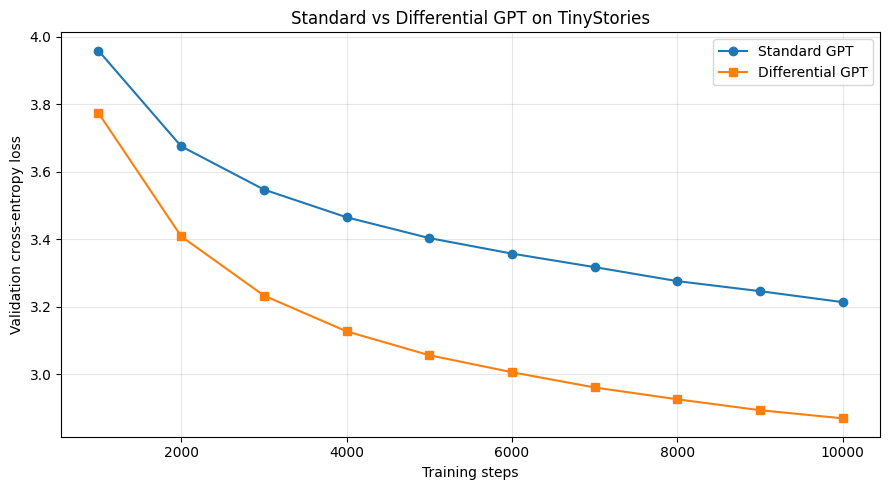

In [90]:

import matplotlib.pyplot as plt

standard_steps = [r["step"] for r in standard_history]
standard_losses = [r["val_loss"] for r in standard_history]

diff_steps = [r["step"] for r in differential_history]
diff_losses = [r["val_loss"] for r in differential_history]

plt.figure(figsize=(9, 5))

plt.plot(
    standard_steps, standard_losses,
    marker="o", label="Standard GPT"
)
plt.plot(
    diff_steps, diff_losses,
    marker="s", label="Differential GPT"
)

plt.xlabel("Training steps")
plt.ylabel("Validation cross-entropy loss")
plt.title("Standard vs Differential GPT on TinyStories")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{CHECKPOINT_DIR}/validation_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# NEEDLE - IN - A -HAY -STACK

In [103]:

experiment_config = {
    "dataset": "TinyStories",
    "train_stories": 25000,
    "validation_stories": 2500,
    "context_length": CONTEXT_LENGTH,
    "embedding_dimension": 128,
    "transformer_layers": 2,
    "standard_attention_heads": 4,
    "differential_attention_heads": 2,
    "training_steps_per_model": 10000,
    "learning_rate": 3e-4,
    "weight_decay": 0.01,
    "batch_size": 16,
    "dropout": 0.1,
    "attention_probability_dropout": 0.0,
    "seed": 42,
}

for key, value in experiment_config.items():
    print(f"{key}: {value}")


dataset: TinyStories
train_stories: 25000
validation_stories: 2500
context_length: 128
embedding_dimension: 128
transformer_layers: 2
standard_attention_heads: 4
differential_attention_heads: 2
training_steps_per_model: 10000
learning_rate: 0.0003
weight_decay: 0.01
batch_size: 16
dropout: 0.1
attention_probability_dropout: 0.0
seed: 42


## Synthetic Retrieval Dataset

In [114]:
retrieval_examples = build_retrieval_examples(
    n_per_position=10,
    seed=123
)

print("Total examples:", len(retrieval_examples))
print("Examples by position:")

for position in ["early", "middle", "late"]:
    count = sum(
        ex["position"] == position
        for ex in retrieval_examples
    )
    print(f"{position.capitalize()}: {count}")

Total examples: 30
Examples by position:
Early: 10
Middle: 10
Late: 10


In [115]:
shared_candidate_sets = make_shared_candidate_sets(
    retrieval_examples,
    seed=789,
    n_candidates=8
)

assert len(shared_candidate_sets) == len(retrieval_examples)
assert all(len(candidates) == 8 for candidates in shared_candidate_sets)

for example, candidates in zip(
    retrieval_examples, shared_candidate_sets
):
    assert example["correct_answer"] in candidates

print("Shared candidate sets created successfully.")
print("Examples:", len(shared_candidate_sets))
print("Candidates per example:", len(shared_candidate_sets[0]))

Shared candidate sets created successfully.
Examples: 30
Candidates per example: 8


In [116]:
def evaluate_shared_sets(model, examples, candidate_sets):
    results = []
    model.eval()

    assert len(examples) == len(candidate_sets)

    for i, (example, candidates) in enumerate(
        zip(examples, candidate_sets)
    ):
        correct_answer = example["correct_answer"]
        assert correct_answer in candidates

        scores = {}

        for candidate in candidates:
            score, token_count = score_candidate_fair(
                model,
                example["prompt"],
                candidate
            )

            assert token_count > 0
            assert math.isfinite(score)
            scores[candidate] = score

        prediction = max(scores, key=scores.get)

        results.append({
            "example": i + 1,
            "position": example["position"],
            "correct_answer": correct_answer,
            "predicted": prediction,
            "is_correct": prediction == correct_answer
        })

    return results


standard_results = evaluate_shared_sets(
    standard_model,
    retrieval_examples,
    shared_candidate_sets
)

differential_results = evaluate_shared_sets(
    differential_model,
    retrieval_examples,
    shared_candidate_sets
)

print("Both models evaluated on identical candidate sets.")

Both models evaluated on identical candidate sets.


In [117]:
def summarize_retrieval(results, model_name):
    total = len(results)

    if total == 0:
        print(f"{model_name}: no results.")
        return

    correct = sum(r["is_correct"] for r in results)

    print(f"\n{model_name}")
    print("-" * 40)
    print(f"Correct: {correct}/{total}")
    print(f"Overall accuracy: {100 * correct / total:.1f}%")

    for position in ["early", "middle", "late"]:
        subset = [
            r for r in results
            if r["position"] == position
        ]

        if subset:
            count = sum(r["is_correct"] for r in subset)
            accuracy = 100 * count / len(subset)

            print(
                f"{position.capitalize():<8}: "
                f"{count}/{len(subset)} ({accuracy:.1f}%)"
            )


summarize_retrieval(
    standard_results, "Standard Transformer"
)

summarize_retrieval(
    differential_results, "Differential Transformer"
)


Standard Transformer
----------------------------------------
Correct: 3/30
Overall accuracy: 10.0%
Early   : 0/10 (0.0%)
Middle  : 2/10 (20.0%)
Late    : 1/10 (10.0%)

Differential Transformer
----------------------------------------
Correct: 6/30
Overall accuracy: 20.0%
Early   : 2/10 (20.0%)
Middle  : 3/10 (30.0%)
Late    : 1/10 (10.0%)


In [118]:
print(
    f"{'ID':<4} {'Position':<8} {'Correct answer':<16} "
    f"{'Standard prediction':<20} "
    f"{'Differential prediction':<22}"
)

for standard, differential in zip(
    standard_results, differential_results
):
    assert standard["example"] == differential["example"]

    print(
        f"{standard['example']:<4} "
        f"{standard['position']:<8} "
        f"{standard['correct_answer']:<16} "
        f"{standard['predicted']:<20} "
        f"{differential['predicted']:<22}"
    )

ID   Position Correct answer   Standard prediction  Differential prediction
1    early    CPJD-958         GMSZ-278             GMSZ-278              
2    early    APCV-486         AREK-282             AREK-282              
3    early    KPUR-371         LXAR-100             LXAR-100              
4    early    WSPX-651         JYSA-500             WSPX-651              
5    early    FLLT-500         KVJP-150             FLLT-500              
6    early    MHNT-613         HELV-484             HELV-484              
7    early    NQBA-237         ZAGG-830             ZAGG-830              
8    early    VCSM-824         VNUZ-882             GJFJ-195              
9    early    JRBT-442         TEUL-149             WTDL-708              
10   early    ZCWB-876         BZRR-983             BZRR-983              
11   middle   SDWF-921         VNXP-665             VNXP-665              
12   middle   ZZZY-784         CERZ-232             AARV-662              
13   middle   DTZM-330  

# Ablation Study
## Acknowledge whether the learnable Lambda actually contributes to the performance of Differential Transformers architecture

In [119]:

# ABALATION STUDY — CELL 1
# Create a separate Differential Transformer with fixed lambda.
# Original classes and trained models remain unchanged.

import random
import numpy as np
import torch

# Reset seeds for reproducible model initialization
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a NEW model using the existing SmallGPT class
fixed_lambda_model = SmallGPT(
    vocab_size=VOCAB_SIZE,
    embed_dim=128,
    num_layers=2,
    num_heads=2,
    context_length=CONTEXT_LENGTH,
    attention_type="differential",
    dropout=0.1
).to(device)

# Fix lambda by making all four lambda vectors zero
fixed_layers = 0

for module in fixed_lambda_model.modules():
    if isinstance(module, DifferentialAttention):

        with torch.no_grad():
            module.lambda_q1.zero_()
            module.lambda_k1.zero_()
            module.lambda_q2.zero_()
            module.lambda_k2.zero_()

        # These parameters should not be updated during training
        module.lambda_q1.requires_grad_(False)
        module.lambda_k1.requires_grad_(False)
        module.lambda_q2.requires_grad_(False)
        module.lambda_k2.requires_grad_(False)

        fixed_layers += 1

assert fixed_layers > 0, (
    "No DifferentialAttention layers found. "
    "Check your SmallGPT attention_type setting."
)

print("Fixed-lambda model created successfully!")
print("Device:", device)
print("Differential attention layers:", fixed_layers)
print("Original differential model unchanged:", differential_model is not fixed_lambda_model)


Fixed-lambda model created successfully!
Device: cuda
Differential attention layers: 2
Original differential model unchanged: True


In [120]:

# ABALATION STUDY — CELL 2
# Verify the effective lambda value in every layer

print("Checking fixed lambda values:")
print("-" * 55)

for layer_number, module in enumerate(
    m for m in fixed_lambda_model.modules()
    if isinstance(m, DifferentialAttention)
):
    lambda_1 = torch.exp(
        torch.sum(module.lambda_q1 * module.lambda_k1).float()
    )
    lambda_2 = torch.exp(
        torch.sum(module.lambda_q2 * module.lambda_k2).float()
    )

    effective_lambda = lambda_1 - lambda_2 + module.lambda_init

    print(f"Layer {layer_number}:")
    print(f"  Initial lambda:   {module.lambda_init:.6f}")
    print(f"  Effective lambda: {effective_lambda.item():.6f}")
    print(
        "  Lambda parameters trainable:",
        any(
            p.requires_grad
            for p in [
                module.lambda_q1,
                module.lambda_k1,
                module.lambda_q2,
                module.lambda_k2
            ]
        )
    )

    assert abs(effective_lambda.item() - module.lambda_init) < 1e-6

print("\nVerification passed: lambda remains fixed.")


Checking fixed lambda values:
-------------------------------------------------------
Layer 0:
  Initial lambda:   0.200000
  Effective lambda: 0.200000
  Lambda parameters trainable: False
Layer 1:
  Initial lambda:   0.355509
  Effective lambda: 0.355509
  Lambda parameters trainable: False

Verification passed: lambda remains fixed.


In [121]:

# ABALATION STUDY — CELL 3
# Train only the new fixed-lambda model

fixed_lambda_history = run_experiment(
    fixed_lambda_model,
    "fixed_lambda_gpt",
    steps=10000,
    eval_interval=1000
)

print("\nFixed-lambda experiment completed!")

print(
    "Final validation loss:",
    round(fixed_lambda_history[-1]["val_loss"], 4)
)
print(
    "Final validation perplexity:",
    round(fixed_lambda_history[-1]["val_ppl"], 2)
)


fixed_lambda_gpt | Step 1000/10000 | Train loss: 3.8836 | Val loss: 3.7727 | Val PPL: 43.50 | Time: 0.9 min
fixed_lambda_gpt | Step 2000/10000 | Train loss: 3.2910 | Val loss: 3.3939 | Val PPL: 29.78 | Time: 1.6 min
fixed_lambda_gpt | Step 3000/10000 | Train loss: 3.0513 | Val loss: 3.2211 | Val PPL: 25.06 | Time: 2.3 min
fixed_lambda_gpt | Step 4000/10000 | Train loss: 3.0939 | Val loss: 3.1158 | Val PPL: 22.55 | Time: 3.2 min
fixed_lambda_gpt | Step 5000/10000 | Train loss: 3.1439 | Val loss: 3.0433 | Val PPL: 20.98 | Time: 3.9 min
fixed_lambda_gpt | Step 6000/10000 | Train loss: 2.8412 | Val loss: 2.9938 | Val PPL: 19.96 | Time: 4.7 min
fixed_lambda_gpt | Step 7000/10000 | Train loss: 3.0471 | Val loss: 2.9519 | Val PPL: 19.14 | Time: 5.4 min
fixed_lambda_gpt | Step 8000/10000 | Train loss: 2.8410 | Val loss: 2.9116 | Val PPL: 18.39 | Time: 6.1 min
fixed_lambda_gpt | Step 9000/10000 | Train loss: 2.9463 | Val loss: 2.8847 | Val PPL: 17.90 | Time: 6.8 min
fixed_lambda_gpt | Step 1000

In [122]:

# ABALATION STUDY — CELL 4
# Compare final validation results

results = [
    (
        "Standard Transformer",
        standard_history[-1]["val_loss"],
        standard_history[-1]["val_ppl"]
    ),
    (
        "Learned-lambda Diff.",
        differential_history[-1]["val_loss"],
        differential_history[-1]["val_ppl"]
    ),
    (
        "Fixed-lambda Diff.",
        fixed_lambda_history[-1]["val_loss"],
        fixed_lambda_history[-1]["val_ppl"]
    )
]

print("=" * 65)
print(f"{'Model':<27}{'Validation Loss':>18}{'Validation PPL':>18}")
print("=" * 65)

for name, loss, ppl in results:
    print(f"{name:<27}{loss:>18.4f}{ppl:>18.2f}")

print("=" * 65)


Model                         Validation Loss    Validation PPL
Standard Transformer                   3.2135             24.87
Learned-lambda Diff.                   2.8688             17.62
Fixed-lambda Diff.                     2.8559             17.39


In [123]:

# ABALATION STUDY — CELL 5
# Compare learned lambda against fixed lambda

learned_loss = differential_history[-1]["val_loss"]
learned_ppl = differential_history[-1]["val_ppl"]

fixed_loss = fixed_lambda_history[-1]["val_loss"]
fixed_ppl = fixed_lambda_history[-1]["val_ppl"]

loss_change = (
    (fixed_loss - learned_loss) / learned_loss
) * 100

ppl_change = (
    (fixed_ppl - learned_ppl) / learned_ppl
) * 100

print("ABLATION ANALYSIS")
print("-" * 45)
print(f"Learned-lambda validation loss: {learned_loss:.4f}")
print(f"Fixed-lambda validation loss:   {fixed_loss:.4f}")
print(f"Relative loss change:           {loss_change:+.2f}%")
print()
print(f"Learned-lambda perplexity:      {learned_ppl:.2f}")
print(f"Fixed-lambda perplexity:        {fixed_ppl:.2f}")
print(f"Relative perplexity change:     {ppl_change:+.2f}%")

if fixed_ppl > learned_ppl:
    print(
        "\nInterpretation: The fixed-lambda model has higher perplexity. "
        "This result is consistent with learned lambda helping on this run."
    )
elif fixed_ppl < learned_ppl:
    print(
        "\nInterpretation: The fixed-lambda model has lower perplexity. "
        "Learning lambda did not improve this metric in this run."
    )
else:
    print("\nInterpretation: Both models have equal final perplexity.")


ABLATION ANALYSIS
---------------------------------------------
Learned-lambda validation loss: 2.8688
Fixed-lambda validation loss:   2.8559
Relative loss change:           -0.45%

Learned-lambda perplexity:      17.62
Fixed-lambda perplexity:        17.39
Relative perplexity change:     -1.29%

Interpretation: The fixed-lambda model has lower perplexity. Learning lambda did not improve this metric in this run.




To study the effect of the learnable lambda parameter, I compared the original Differential Transformer with a modified version in which lambda was fixed at its initial value. The other model components and training settings were kept unchanged.

The Standard Transformer achieved a validation loss of 3.2135 and perplexity of 24.87. The learned-lambda Differential Transformer achieved a validation loss of 2.8688 and perplexity of 17.62, while the fixed-lambda version achieved a validation loss of 2.8559 and perplexity of 17.39.

The fixed-lambda model showed a 0.45% reduction in validation loss and a 1.29% reduction in perplexity compared with the learned-lambda model. Therefore, learning lambda did not improve validation performance in this particular experiment. However, the difference was small, and the experiment used a single seed and a reduced-scale model. Further experiments with multiple seeds would be needed to determine whether this difference is consistent.

# FINAL PLOTS


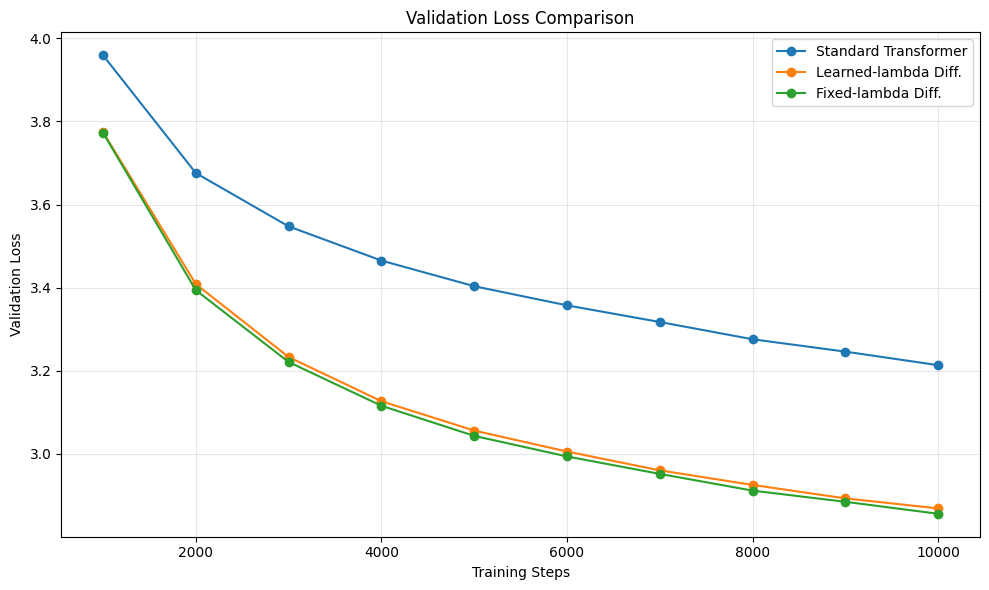

In [124]:

# STEP 1: Compare training and validation loss

import matplotlib.pyplot as plt

histories = {
    "Standard Transformer": standard_history,
    "Learned-lambda Diff.": differential_history,
    "Fixed-lambda Diff.": fixed_lambda_history
}

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    steps = [item["step"] for item in history]
    val_losses = [item["val_loss"] for item in history]

    plt.plot(steps, val_losses, marker="o", label=name)

plt.xlabel("Training Steps")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


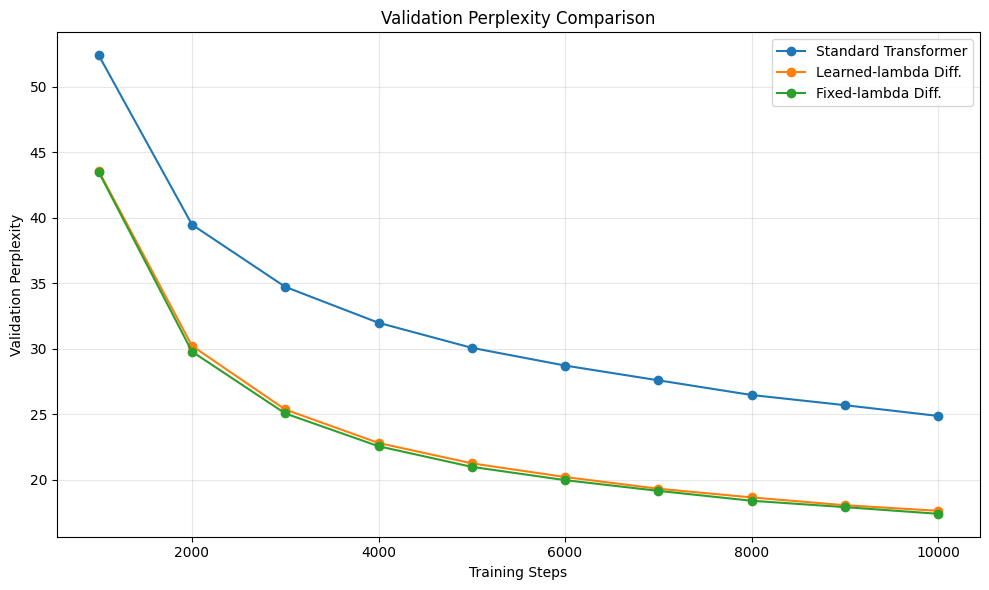

In [125]:

# STEP 2: Compare validation perplexity

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    steps = [item["step"] for item in history]
    val_ppl = [item["val_ppl"] for item in history]

    plt.plot(steps, val_ppl, marker="o", label=name)

plt.xlabel("Training Steps")
plt.ylabel("Validation Perplexity")
plt.title("Validation Perplexity Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Needle in a HayStack with Fixed Lambda model

In [126]:

# RETRIEVAL ABLATION — CELL 1
# Check that the original shared retrieval examples and candidates exist

required_variables = [
    "retrieval_examples",
    "shared_candidate_sets",
    "standard_model",
    "differential_model",
    "fixed_lambda_model"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'MISSING'}")

assert "retrieval_examples" in globals(), (
    "Run the cell that creates retrieval_examples first."
)
assert "shared_candidate_sets" in globals(), (
    "Run the cell that creates shared_candidate_sets first."
)

print("\nNumber of retrieval examples:", len(retrieval_examples))
print("Number of candidate sets:", len(shared_candidate_sets))


retrieval_examples: Available
shared_candidate_sets: Available
standard_model: Available
differential_model: Available
fixed_lambda_model: Available

Number of retrieval examples: 30
Number of candidate sets: 30


In [127]:

# RETRIEVAL ABLATION — CELL 2
# Evaluate fixed lambda using the same candidate sets

fixed_lambda_retrieval = evaluate_shared_sets(
    fixed_lambda_model,
    retrieval_examples,
    shared_candidate_sets
)

fixed_correct = sum(
    result["is_correct"] for result in fixed_lambda_retrieval
)

fixed_total = len(fixed_lambda_retrieval)
fixed_accuracy = 100 * fixed_correct / fixed_total

print("Fixed-lambda retrieval results")
print("-" * 40)
print(f"Correct predictions: {fixed_correct}/{fixed_total}")
print(f"Retrieval accuracy: {fixed_accuracy:.2f}%")


Fixed-lambda retrieval results
----------------------------------------
Correct predictions: 5/30
Retrieval accuracy: 16.67%


In [130]:

# RETRIEVAL ABLATION — CELL 3
# Summarize all models on the same retrieval task

standard_retrieval_accuracy = (
    100 * sum(r["is_correct"] for r in standard_results)
    / len(standard_results)
)

learned_retrieval_accuracy = (
    100 * sum(r["is_correct"] for r in differential_results)
    / len(differential_results)
)

retrieval_comparison = [
    ("Standard Transformer", standard_retrieval_accuracy),
    ("Learned-lambda Diff.", learned_retrieval_accuracy),
    ("Fixed-lambda Diff.", fixed_accuracy)
]

print("=" * 55)
print(f"{'Model':<27}{'Correct':>10}{'Accuracy':>15}")
print("=" * 55)

result_lists = [
    standard_results,
    differential_results,
    fixed_lambda_retrieval
]

for (name, accuracy), results in zip(
    retrieval_comparison, result_lists
):
    correct = sum(r["is_correct"] for r in results)
    total = len(results)
    print(f"{name:<27}{correct:>5}/{total:<5}{accuracy:>10.2f}%")

print("=" * 55)


Model                         Correct       Accuracy
Standard Transformer           3/30        10.00%
Learned-lambda Diff.           6/30        20.00%
Fixed-lambda Diff.             5/30        16.67%


In [132]:

# RETRIEVAL ABLATION — CELL 4
# Accuracy by needle position

positions = ["early", "middle", "late"]
all_retrieval_results = {
    "Standard": standard_results,
    "Learned lambda": differential_results,
    "Fixed lambda": fixed_lambda_retrieval
}

print(f"{'Position':<12}{'Standard':>12}{'Learned λ':>14}{'Fixed λ':>12}")
print("-" * 50)

for position in positions:
    row_values = []

    for model_name, results in all_retrieval_results.items():
        subset = [
            r for r in results
            if r["position"] == position
        ]

        correct = sum(r["is_correct"] for r in subset)
        accuracy = 100 * correct / len(subset) if subset else 0
        row_values.append(f"{correct}/{len(subset)} ({accuracy:.0f}%)")

    print(
        f"{position:<12}"
        f"{row_values[0]:>12}"
        f"{row_values[1]:>14}"
        f"{row_values[2]:>12}"
    )


Position        Standard     Learned λ     Fixed λ
--------------------------------------------------
early          0/10 (0%)    2/10 (20%)  1/10 (10%)
middle        2/10 (20%)    3/10 (30%)  3/10 (30%)
late          1/10 (10%)    1/10 (10%)  1/10 (10%)


### Needle-in-a-Haystack Retrieval Evaluation

I evaluated all three models on the same 30 synthetic retrieval examples using shared candidate sets. The Standard Transformer correctly retrieved 3 answers, giving an accuracy of 10%. The learned-lambda Differential Transformer correctly retrieved 6 answers (20%), while the fixed-lambda version retrieved 5 answers (16.67%).

When the examples were grouped by the position of the answer in the context, both Differential variants performed better than the Standard Transformer on early-position examples. For middle-position examples, both Differential variants achieved 30% accuracy, compared with 20% for the Standard Transformer. All three models achieved 10% accuracy on late-position examples.

The learned-lambda variant obtained the highest overall retrieval accuracy, whereas the fixed-lambda variant obtained the lowest validation perplexity in the language-modeling experiment. These results indicate that the best-performing variant differed by evaluation metric. However, because the retrieval test used only 30 synthetic examples, the findings should be treated as preliminary rather than conclusive evidence of improved retrieval ability.